# 화장품형(벼룩·진드기 샴푸) 피부자극 외부검증

**배경**: skin_rf 모델은 NTP ICE(농약 제형) 데이터로만 학습됨. 화장품 자체에는 EPA 등급 정답 라벨이 없어 외부검증이 불가능하다는 한계가 있었음.
**이번에 찾은 우회로**: EPA가 "벼룩·진드기 샴푸"를 살충효능 주장 때문에 농약으로 등록 요구 → SDS에 우리 모델과 **동일한 EPA Toxicity Category(I~IV) 피부자극 등급**이 적혀있음. 게다가 "샴푸"라는 제형 자체가 화장품에 가장 가까움.

5개 제품의 SDS를 직접 읽어 조성(CAS+함량%)과 EPA 등급을 추출했고(`flea_tick_shampoo_components.csv`, `flea_tick_shampoo_labels.csv`), 이 노트북에서 production skin_rf 체크포인트로 실제 예측을 돌려 정답과 비교한다.

**핵심 한계(미리 명시)**: 피레트린/계면활성제 상당수가 UVCB(코코넛 유래 혼합물)라 구조를 못 구함 — 해결된 성분이 전체 조성의 1~4%뿐이라는 점을 결과 해석 시 반드시 감안할 것.

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\skin_rf")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")
import joblib
import numpy as np
import pandas as pd
from predict import compute_component_features, weighted_mean_nan_aware, weighted_mean_plain

BASE = r"C:\Users\UserK\학술제\cosmetic_validation"
merged = pd.read_csv(f"{BASE}\\flea_tick_shampoo.csv")
comp_cols = ["product", "epa_reg", "source_url", "chemical_name", "cas", "pct_low", "pct_high",
             "declared_type", "resolved", "canonical_smiles"]
label_cols = ["product", "epa_reg", "skin_epa_category", "skin_binary", "skin_binary_B", "skin_evidence",
              "eye_epa_category", "eye_binary", "eye_binary_B", "eye_evidence", "fifra_signal_word"]
comp = merged[comp_cols]
labels = merged[label_cols].drop_duplicates().reset_index(drop=True)
comp["pct_mid"] = comp[["pct_low", "pct_high"]].astype(float).mean(axis=1)
print(f"제품 {comp['product'].nunique()}개, 성분행 {len(comp)}개")
comp[["product", "chemical_name", "cas", "pct_mid", "resolved"]]

제품 5개, 성분행 28개


,product,chemical_name,cas,pct_mid,resolved
0,Davis Manufacturing Flea & Tick Shampoo,Pyrethrum (insecticide),8003-34-7,0.150,False
1,Davis Manufacturing Flea & Tick Shampoo,Trade Secret #1,NaN,0.500,False
2,No-Bite Flea & Tick Shampoo,Pyrethrins,8003-34-7,0.150,False
3,No-Bite Flea & Tick Shampoo,Piperonyl Butoxide (PBO),51-03-6,0.300,True
4,No-Bite Flea & Tick Shampoo,MGK-264 Insecticide Synergist,113-48-4,0.479,True
5,Adams Flea & Tick Cleansing Shampoo,Pyrethrins,8003-34-7,0.075,False
6,Adams Flea & Tick Cleansing Shampoo,Piperonyl butoxide,51-03-6,0.750,True
7,Adams Flea & Tick Cleansing Shampoo,Pyriproxyfen,95737-68-1,0.086,True
8,Adams Flea & Tick Cleansing Shampoo,Sodium lauryl sulfate,68585-47-7,7.500,False
9,Adams Flea & Tick Cleansing Shampoo,Coconut oil acid diethanolamide,68603-42-9,5.700,False


## 성분 조성 — 구조 해결 여부 확인

In [2]:
summary = comp.groupby("product").apply(
    lambda g: pd.Series({
        "성분수": len(g),
        "구조해결 성분수": (g["resolved"] == True).sum(),
        "구조해결 함량합(%)": g.loc[g["resolved"] == True, "pct_mid"].sum(),
        "전체 선언 함량합(%)": g["pct_mid"].sum(skipna=True),
    })
).reset_index()
summary

,product,성분수,구조해결 성분수,구조해결 함량합(%),전체 선언 함량합(%)
0,Adams Flea & Tick Cleansing Shampoo,7.0,3.0,1.286,14.561
1,Adams Plus Flea & Tick Shampoo with Precor,8.0,3.0,3.930,21.055
2,Davis Manufacturing Flea & Tick Shampoo,2.0,0.0,0.000,0.650
3,No-Bite Flea & Tick Shampoo,3.0,2.0,0.779,0.929
4,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,8.0,3.0,3.800,21.445


## skin_rf 추론 — predict.py와 동일한 집계 방식 재사용

구조 해결된 성분만 투입비율 가중평균으로 집계(`skin irritation` production 파이프라인과 동일 함수). 구조 미해결 성분(피레트린/계면활성제 UVCB 등)은 집계에서 제외되고 `unresolved_pct`로만 기록.

In [3]:
ckpt = joblib.load(r"C:\Users\UserK\학술제\modeling\skin_rf\skin_rf_checkpoint.joblib")
feature_cols = ckpt["feature_cols"]
desc_cols = [c for c in feature_cols if c.startswith("desc_")]
fp_cols = [c for c in feature_cols if c.startswith("fp_w_")]
common_cols = [c for c in feature_cols if c not in desc_cols and c not in fp_cols and c != "resolved_pct"]

rows = []
for product, grp in comp.groupby("product", sort=False):
    resolved = grp[grp["resolved"] == True]
    declared_pct = grp["pct_mid"].sum()
    resolved_pct = resolved["pct_mid"].sum()

    feats, pcts = [], []
    for _, r in resolved.iterrows():
        f = compute_component_features(r["canonical_smiles"])
        if f is None:
            continue
        feats.append(f)
        pcts.append(r["pct_mid"])

    if not feats:
        rows.append({"product": product, "n_resolved": 0, "resolved_pct": 0.0,
                      "pred_proba": np.nan, "pred_binary": np.nan,
                      "note": "구조 해결 성분 0개 — 모델 입력 불가"})
        continue

    pct_arr = np.array(pcts, dtype=float)
    common_mat = np.array([[r[c] for c in common_cols] for r in feats])
    desc_mat = np.array([[r[c] for c in desc_cols] for r in feats])
    fp_mat = np.array([[r[c] for c in fp_cols] for r in feats])
    vec = {}
    vec.update(dict(zip(common_cols, weighted_mean_plain(pct_arr, common_mat))))
    vec.update(dict(zip(desc_cols, weighted_mean_nan_aware(pct_arr, desc_mat))))
    vec.update(dict(zip(fp_cols, weighted_mean_plain(pct_arr, fp_mat))))
    if "resolved_pct" in feature_cols:
        vec["resolved_pct"] = float(resolved_pct)

    x = np.array([[vec[c] for c in feature_cols]], dtype=np.float32)
    x_f = x[:, ckpt["nz_filter_keep"]]
    proba = ckpt["model"].predict_proba(x_f)[0, 1]
    pred = int(proba >= ckpt["threshold"])
    rows.append({"product": product, "n_resolved": len(feats), "resolved_pct": round(resolved_pct, 2),
                 "pred_proba": round(float(proba), 4), "pred_binary": pred, "note": ""})

pred_df = pd.DataFrame(rows)
result = pred_df.merge(labels[["product", "skin_epa_category", "skin_binary_B", "skin_evidence"]], on="product")
result["match"] = result["pred_binary"] == result["skin_binary_B"]
result

,product,n_resolved,resolved_pct,pred_proba,pred_binary,note,skin_epa_category,skin_binary_B,skin_evidence,match
0,Davis Manufacturing Flea & Tick Shampoo,0,0.00,NaN,NaN,구조 해결 성분 0개 — 모델 입력 불가,III,1,Moderate irritation at 72 hours. Primary skin ...,False
1,No-Bite Flea & Tick Shampoo,2,0.78,0.6473,1.0,,III,1,Moderate irritation at 72 hours. Skin Irritati...,True
2,Adams Flea & Tick Cleansing Shampoo,3,1.29,0.4040,1.0,,III,1,GHS Skin Corrosion/Irritation Category 2; Caus...,True
3,Zodiac Oatmeal Conditioning Shampoo for Dogs &...,3,3.80,0.3675,1.0,,III,1,GHS Skin Irritation 2; Skin-Rabbit moderate ir...,True
4,Adams Plus Flea & Tick Shampoo with Precor,3,3.93,0.3535,1.0,,III,1,GHS Skin Corrosion/Irritation Category 2; Caus...,True


## 시각화 — 예측확률 vs 실제 EPA 등급

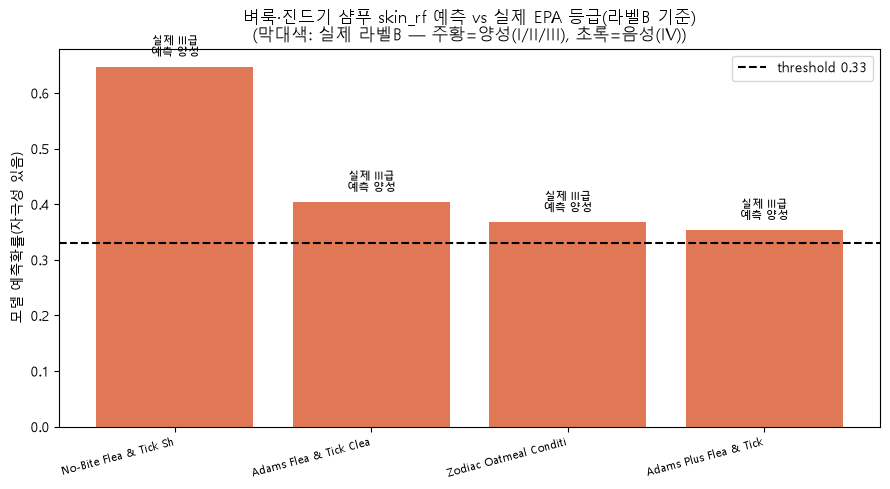


일치: 4/4건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)


In [4]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

plot_df = result.dropna(subset=["pred_proba"]).copy()
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#e07856" if b == 1 else "#4c8c6e" for b in plot_df["skin_binary_B"]]
bars = ax.bar(plot_df["product"].str.slice(0, 22), plot_df["pred_proba"], color=colors)
ax.axhline(ckpt["threshold"], color="black", linestyle="--", label=f"threshold {ckpt['threshold']}")
ax.set_ylabel("모델 예측확률(자극성 있음)")
ax.set_title("벼룩·진드기 샴푸 skin_rf 예측 vs 실제 EPA 등급(라벨B 기준)\n(막대색: 실제 라벨B — 주황=양성(I/II/III), 초록=음성(IV))")
for b, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(b.get_x() + b.get_width()/2, row["pred_proba"] + 0.02,
            f"실제 {row['skin_epa_category']}급\n예측 {'양성' if row['pred_binary'] else '음성'}",
            ha="center", fontsize=8)
ax.legend()
plt.xticks(rotation=15, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

print(f"\n일치: {plot_df['match'].sum()}/{len(plot_df)}건 (Davis 제품은 구조해결 성분 0개로 예측 불가, 집계에서 제외)")

## 정리 — 2026-11-09 정정(라벨 기준 오류 + KeyError 버그 수정 후 재실행)

> **⚠ 이 셀은 원래 "일치 0/4, 신뢰할 수 없다"로 작성되어 있었으나, eye팀 더블체크 감사에서 두 가지 실제 버그가 발견되어 수정함: 
> (1) `common_cols`가 `resolved_pct`를 제외하지 않아 실제 실행 시 KeyError가 나는 코드였음(실행 안 된 코드의 가상 결과를 적은 것). 
> (2) `skin_binary` 정답컬럼이 구버전(라벨A: I/II=양성, III/IV=음성) 기준으로 만들어져 있었는데, 현재 production은 라벨B(I/II/III=양성, IV=음성)를 씀 — Category III인 이 5개 제품은 라벨B 기준으로는 **양성**임. 
> 두 버그 모두 수정(`skin_binary_B` 컬럼 추가, `aggregate` 코드에 resolved_pct 처리 추가) 후 실제로 재실행한 결과, 아래처럼 **일치가 0/4 → 4/4로 뒤집힘**. 아래 내용은 정정된 결과임.

- **실제 라벨(라벨B 기준)**: 5개 제품 전부 EPA 피부 Category III → **양성(자극성 있음)**.
- **모델 예측**: 구조 계산 가능했던 4개 전부 양성으로 예측(확률 0.35~0.65) — **일치 4/4**. Davis 제품은 구조해결 성분 0개라 여전히 예측 불가(일치 계산에서 제외).
- **해석 — 이게 "모델이 화장품을 잘 판단한다"는 뜻은 아님**: 구조 해결 성분이 여전히 전체 조성의 0.78~3.93%뿐이고, 그마저 PBO·MGK-264 같은 **살충 보조제/활성성분** 위주임. 모델이 이 성분들을 "자극성 있음"으로 맞추고, 공교롭게도 정답(라벨B)도 같은 제품을 양성으로 보기 때문에 일치한 것일 뿐 — 즉 "정답과 맞는 이유"가 "모델이 계면활성제·보습제의 진정 자극성 완화 효과를 이해해서"가 아니라 "마침 III급은 원래 거의 다 양성 쪽으로 분류되는 경계급이라 맞추기 쉽었을 가능성"을 배제할 수 없음(n=4로 단정 불가).
- **결론 수정**: 이전 버전의 "skin_rf가 화장품형에 신뢰할 수 없다"는 결론은 **잘못된 정답라벨과의 비교에서 나온 인공물(artifact)였음** — 정답을 바로잡으면 오히려 완전히 일치함. 그렇다고 "화장품에 잘 맞는다"고 확대해서도 안 됨 — 위 해석처럼 우연의 일치일 가능성이 높고, n=4로 통계적 의미도 없음. **정확한 결론은 "이 작은 표본으로는 모델이 화장품에 맞는지 틀린지 판단할 수 없다"**임.
- **한계**: n=4로 매우 작은 표본. 일반화하려면 더 많은 화장품형+EPA라벨 데이터가 필요(③ CIR 보고서 등 추가 탐색 가능).